# Proyecto Final Integrador – Grupo 6
**Percepción y navegación de un vehículo autónomo urbano** · Demostración de C1, C2 y C3

Sebastián Páez Castañeda · Johan Sebastián Acuña · Santiago Felipe Fajardo — Docente: Juan David Rodríguez Martínez

Este cuaderno muestra cada componente con un ejemplo pequeño y resume los experimentos (que se generan con `python -m experimentos.ejecutar_todos`).

In [1]:
import os, sys, json
RAIZ = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, RAIZ)
import matplotlib.pyplot as plt
from IPython.display import Image, display
from datos import generador as g
RES = os.path.join(RAIZ, 'resultados')

## C1 · Par de puntos más cercanos (divide y vencerás)
$T(n) = 2T(n/2) + \Theta(n)$ → Teorema Maestro caso 2 ($a=2$, $b=2$, $f(n)=\Theta(n)=\Theta(n^{\log_2 2})$) → $\Theta(n\log n)$.

D&V: d = 0.018336 m entre (773.4038181194117, 436.6863438727977) y (773.3915111814006, 436.699936631233)


Fuerza bruta: d = 0.018336 m
distancias calculadas D&V = 2112 vs fuerza bruta = 1999000
máximo de vecinos revisados en la franja = 2 (cota teórica 7)


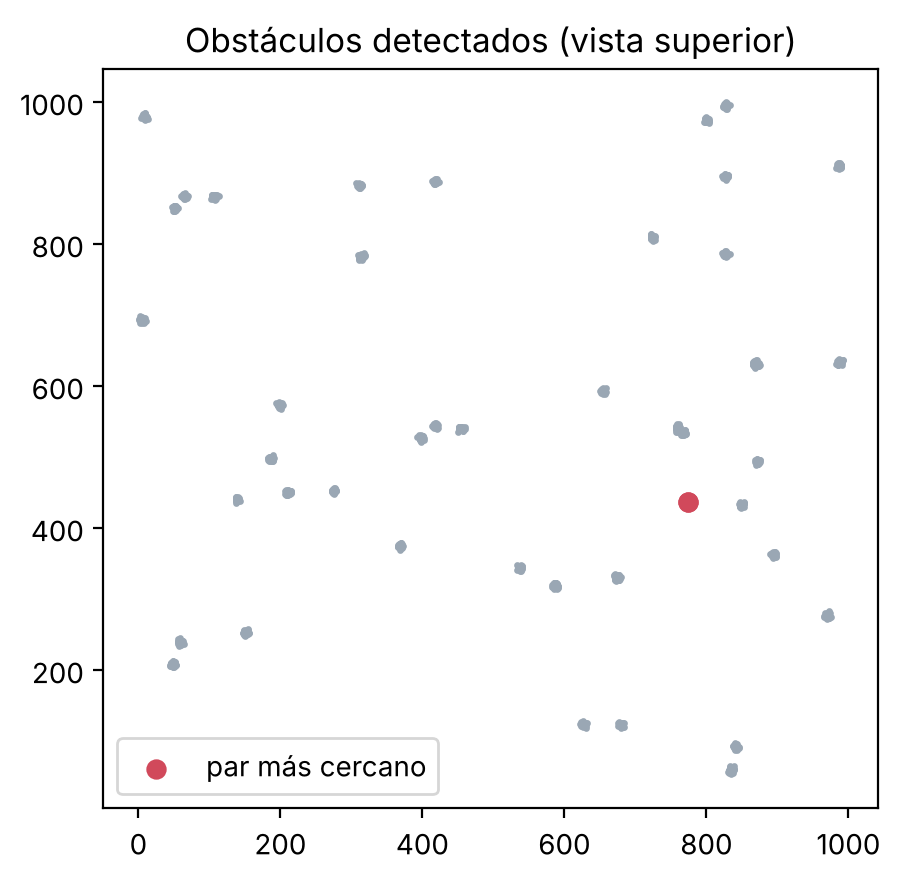

In [2]:
from c1_par_mas_cercano.par_cercano import par_mas_cercano, fuerza_bruta, Contador
pts = g.nube_puntos_2d(2000, 'agrupada')
c = Contador()
d, p, q = par_mas_cercano(pts, c)
print(f'D&V: d = {d:.6f} m entre {p} y {q}')
print(f'Fuerza bruta: d = {fuerza_bruta(pts)[0]:.6f} m')
print(f'distancias calculadas D&V = {c.distancias} vs fuerza bruta = {2000*1999//2}')
print(f'máximo de vecinos revisados en la franja = {c.max_por_punto_franja} (cota teórica 7)')
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(*zip(*pts), s=2, color='#9aa7b4')
ax.scatter(*zip(p, q), s=40, color='#d1495b', label='par más cercano')
ax.set_aspect('equal'); ax.legend(); ax.set_title('Obstáculos detectados (vista superior)'); plt.show()

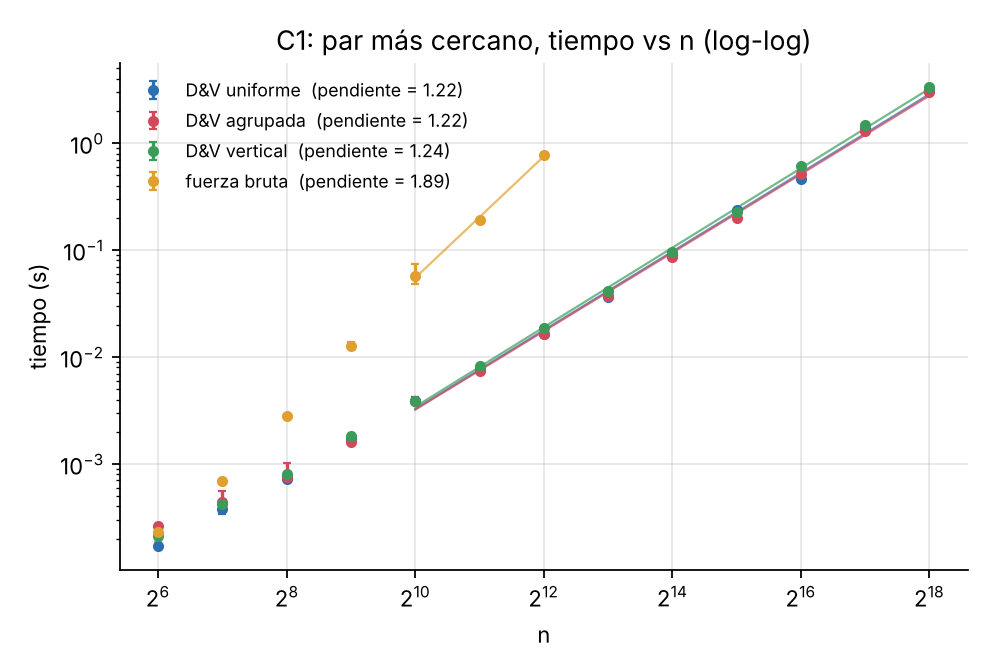

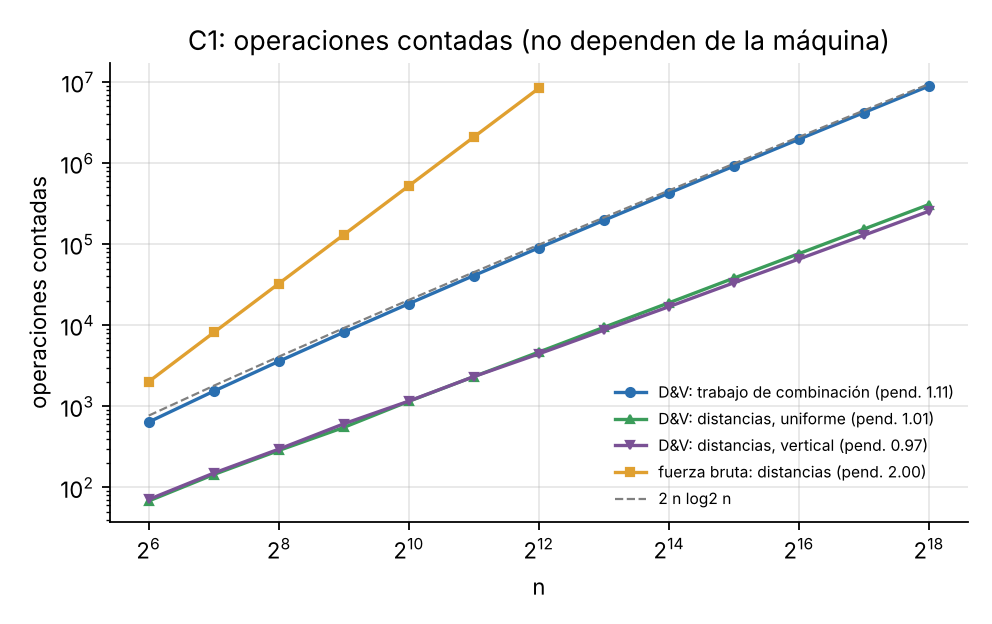

In [3]:
display(Image(os.path.join(RES, 'c1_loglog.png')))
display(Image(os.path.join(RES, 'c1_operaciones.png')))

## C2 · Mapa de vóxeles como tabla hash con duplicación
Método contable: cada inserción nueva paga 3 créditos (1 para colocarse + 2 para el próximo rehash).

puntos = 50000, vóxeles ocupados N = 26460, capacidad m = 65536, α = 0.404
rejilla densa = 2,097,152 celdas
costo real total = 99146 <= costo amortizado = 102920; banco mínimo = 0


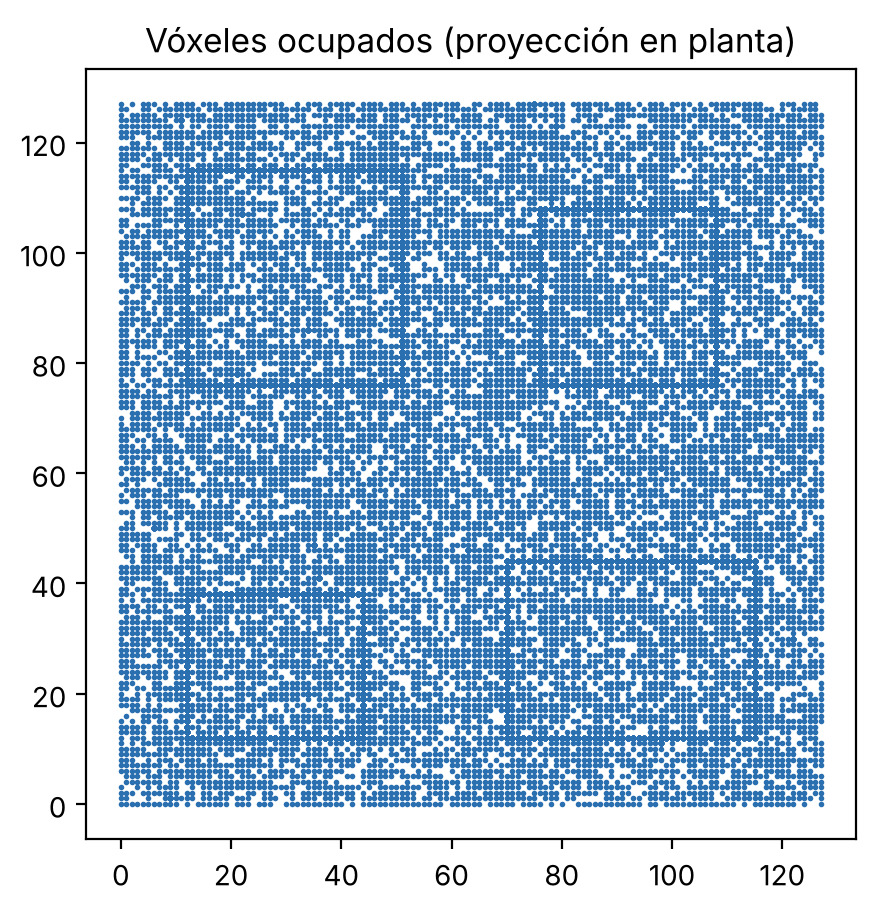

In [4]:
from c2_mapa_voxeles.mapa_voxeles import construir_mapa, celdas_rejilla_densa
escena = g.escena_urbana_3d(50000)
mapa = construir_mapa(escena, r=0.5, instrumentar=True)
print(f'puntos = {len(escena)}, vóxeles ocupados N = {len(mapa)}, capacidad m = {mapa.capacidad}, α = {mapa.factor_carga():.3f}')
print(f'rejilla densa = {celdas_rejilla_densa(64, 0.5):,} celdas')
print(f'costo real total = {mapa.costo_real_total} <= costo amortizado = {mapa.costo_amortizado_total}; banco mínimo = {mapa.banco_minimo}')
xs = [k[0] for k, _ in mapa.items()]; ys = [k[1] for k, _ in mapa.items()]
fig, ax = plt.subplots(figsize=(5, 5)); ax.scatter(xs, ys, s=1, color='#2a6fb0')
ax.set_aspect('equal'); ax.set_title('Vóxeles ocupados (proyección en planta)'); plt.show()

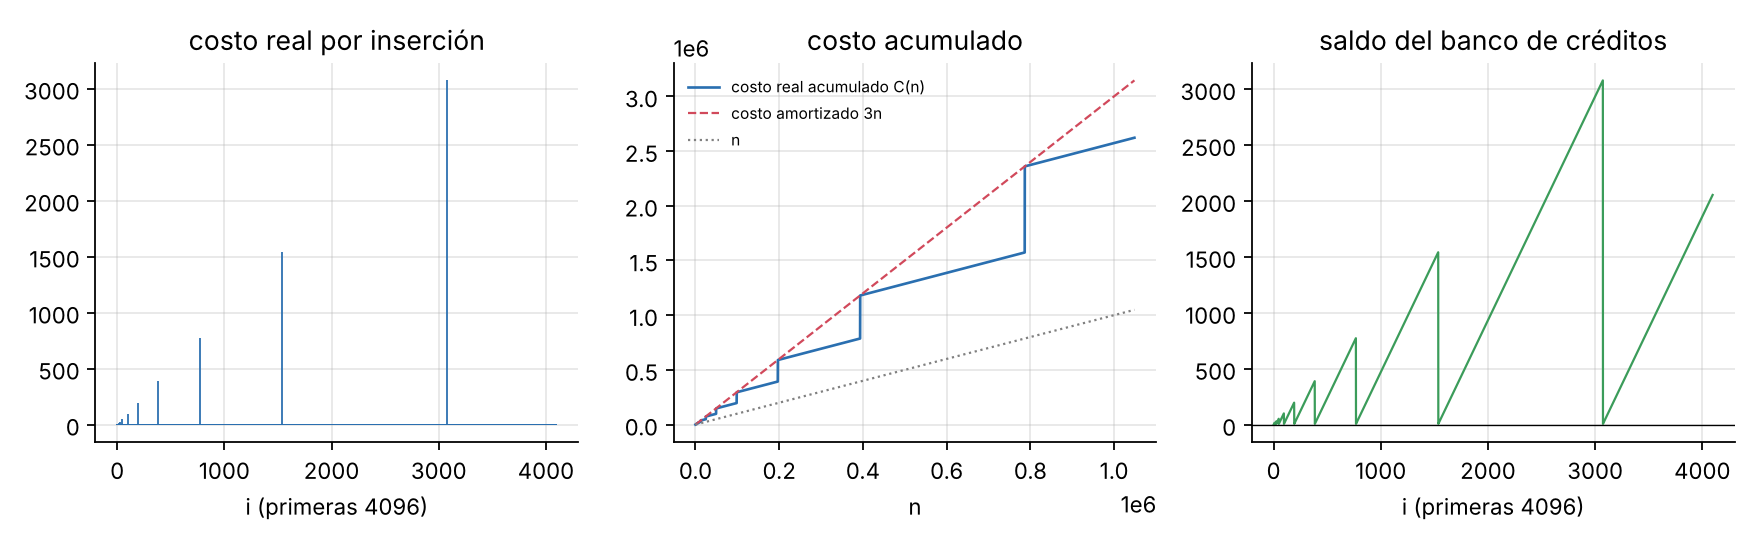

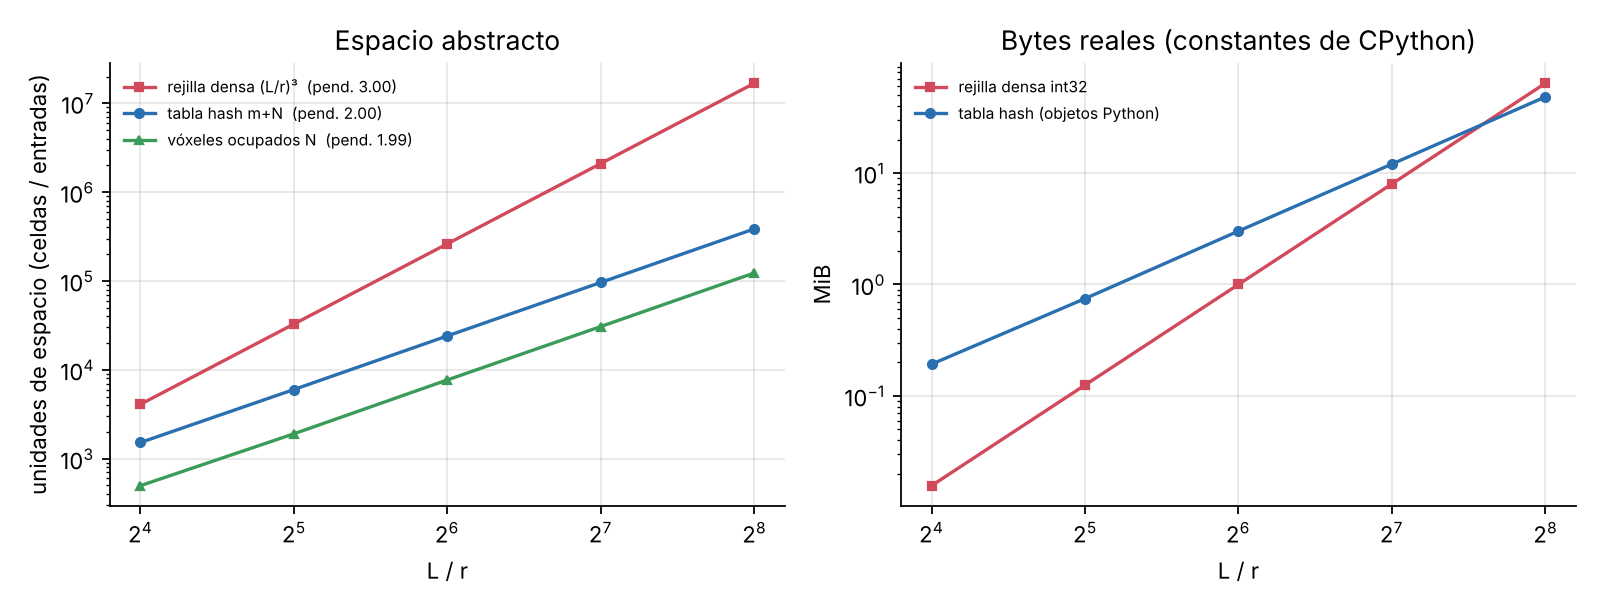

In [5]:
display(Image(os.path.join(RES, 'c2_metodo_contable.png')))
display(Image(os.path.join(RES, 'c2_espacio.png')))

## C3 · Voraz: cobertura mínima de la trayectoria [0, L]
Regla: entre los tramos que empiezan dentro de lo ya cubierto, elegir el que llega más lejos.

voraz (llega más lejos): [(0, 5), (5, 10)]
más largo primero      : [(2, 8), (0, 5), (5, 10)] <- contraejemplo, no es óptimo


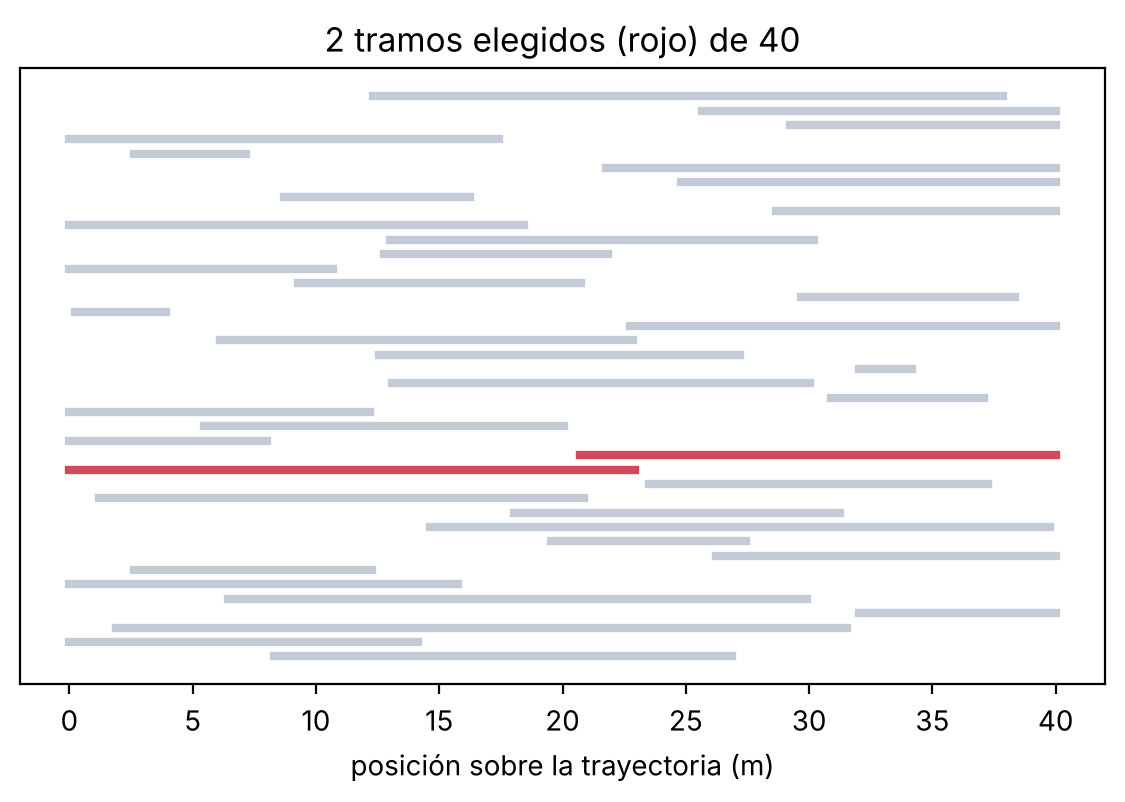

In [6]:
from c3_cobertura_intervalos.cobertura import cobertura_minima, voraz_mas_largo
ej = [(0, 5), (5, 10), (2, 8)]
print('voraz (llega más lejos):', cobertura_minima(ej, 10))
print('más largo primero      :', voraz_mas_largo(ej, 10), '<- contraejemplo, no es óptimo')
tramos, L = g.tramos_sensado(40)
sol = cobertura_minima(tramos, L)
fig, ax = plt.subplots(figsize=(7, 4))
for i, (a, b) in enumerate(tramos):
    ax.plot([a, b], [i, i], color='#d1495b' if (a, b) in sol else '#c3ccd6', lw=3)
ax.set_xlabel('posición sobre la trayectoria (m)'); ax.set_yticks([])
ax.set_title(f'{len(sol)} tramos elegidos (rojo) de {len(tramos)}'); plt.show()

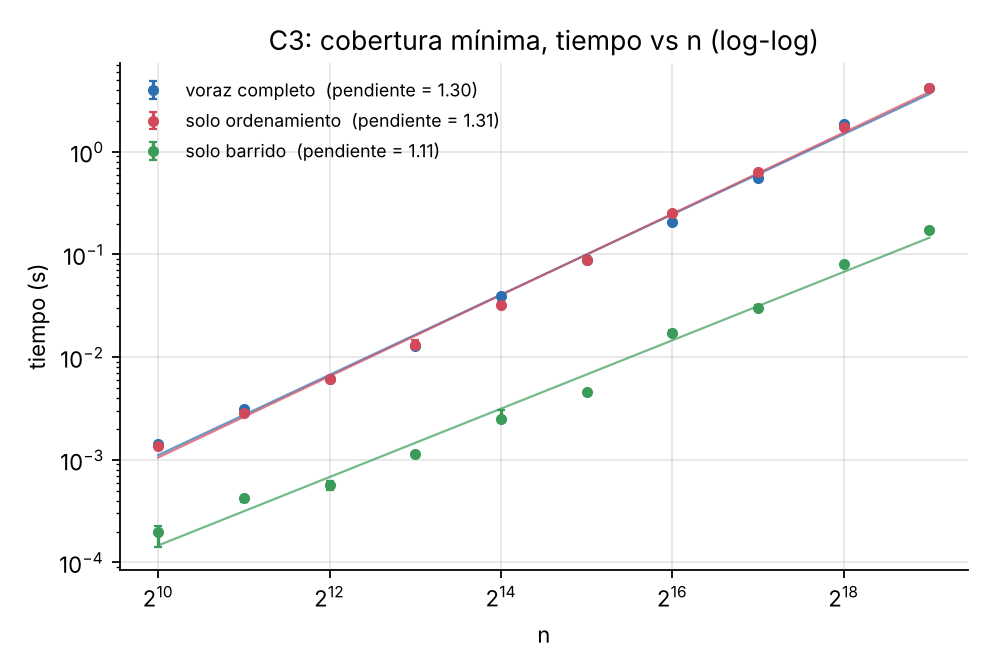

{
 "instancias": 2000,
 "factibles": 321,
 "voraz_igual_al_optimo": 321,
 "infactibles_detectadas": 1679,
 "infactibles": 1679,
 "mas_largo_primero_suboptimo": 216,
 "exceso_maximo_mas_largo": 4,
 "ejemplo_suboptimo": {
  "tramos": [
   [
    7.31,
    10.36
   ],
   [
    -0.91,
    2.26
   ],
   [
    4.38,
    5.55
   ],
   [
    3.15,
    4.65
   ],
   [
    9.34,
    10.91
   ],
   [
    4.25,
    9.03
   ],
   [
    -0.24,
    3.35
   ],
   [
    -0.4,
    4.14
   ],
   [
    8.65,
    10.7
   ],
   [
    8.23,
    10.51
   ],
   [
    5.46,
    7.94
   ]
  ],
  "largo": 10.0,
  "optimo"


In [7]:
display(Image(os.path.join(RES, 'c3_loglog.png')))
print(json.dumps(json.load(open(os.path.join(RES, 'c3_resumen.json')))['optimalidad'], indent=1, ensure_ascii=False)[:600])